# PhyRes Demo: Physics-Residual Control on a Swinging Pendulum

This notebook is a guided tour of the **PhyRes** engine, applied to the task
where the residual-physics idea pays off most: **pendulum swing-up** under a
misspecified analytic prior. The pendulum is nonlinear and underactuated (the
torque limit is below the gravity torque, so the controller must *pump
energy* through several swings). Its reality gap (viscous and quadratic drag,
dry Coulomb friction, and misidentified mass and length) is one the
frictionless prior has no way to represent.

We will:

1. Instantiate the `pendulum` benchmark task through the task-agnostic engine.
2. Collect a small exploratory dataset from the *true* system.
3. Train a **physics-residual deep ensemble** world model on top of the
   (deliberately naive) analytic prior.
4. Compare one-step prediction error: **analytic prior vs. residual
   ensemble** (about a 148x RMSE reduction here, the largest in the suite).
5. Plot the ensemble's **epistemic uncertainty** as a 2D heat map over the
   pendulum's full state space, and watch it spike out of distribution.
6. Run closed-loop swing-up with the **CEM** planner and compare three world
   models side by side: the misspecified prior alone (which never swings up),
   the residual ensemble (optimistic), and the residual ensemble with its
   epistemic-uncertainty penalty.

Everything below is pure NumPy, plus `matplotlib`/`seaborn` for plotting only
(see the `notebook` extra in `pyproject.toml`). Background and citations are
in [SCIENCE.md](SCIENCE.md). The engine's abstractions are in
[src/phyres/environments/base.py](src/phyres/environments/base.py).

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from phyres.data import collect_random_rollouts
from phyres.ensemble import ResidualEnsembleWorldModel
from phyres.environments import make_task
from phyres.environments.base import wrap_angle
from phyres.planners import CEMPlanner

warnings.filterwarnings("ignore")
SEED = 0
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"prior": "#9aa5b1", "model": "#2f6fed", "uncertainty": "#e0621f", "trajectory": "#1f9e6e"}
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"


## 1. The benchmark task: a pendulum with an unmodeled reality gap

`make_task("pendulum", seed=SEED)` builds a matched `PendulumPrior` /
`PendulumSystem` pair (see
[src/phyres/environments/pendulum.py](src/phyres/environments/pendulum.py))
plus a swing-up cost function. It is exactly the same `BenchmarkTask`
contract the cart-pole and quadrotor tasks use, which is what makes the
engine task-agnostic.

State `s = (theta, omega)`, with `theta` the angle from the *upright*
equilibrium (`theta = 0`) and `omega` the angular velocity. The action is a
scalar torque `u` in `[-u_max, u_max]`.

* **`PendulumPrior`** assumes a frictionless rigid body with *misidentified*
  mass and length (`m != m*`, `l != l*`). Even the gravity-torque term itself
  is wrong, not just the friction.
* **`PendulumSystem`** (the "real world") adds viscous damping, quadratic
  aerodynamic drag and dry Coulomb friction on top of the heavier, longer
  pendulum. These are three unmodeled force terms the prior has no way to
  represent.

In [2]:
task = make_task("pendulum", seed=SEED)
prior, true_system = task.prior, task.true_system

print(f"task: {task.name!r}")
print(f"state_dim={prior.state_dim}  action_dim={prior.action_dim}  "
      f"action bounds=[{prior.action_low}, {prior.action_high}]")
print(f"prior:      mass={prior.mass} kg  length={prior.length} m  damping={prior.damping}")
print(f"true system: mass={true_system.mass} kg  length={true_system.length} m")
print()
print("reality gap (true system only):")
print(f"  viscous damping    : {true_system.damping}")
print(f"  quadratic drag     : {true_system.quad_drag}")
print(f"  Coulomb friction   : {true_system.coulomb}")


task: 'pendulum'
state_dim=2  action_dim=1  action bounds=[[-3.5], [3.5]]
prior:      mass=1.0 kg  length=1.0 m  damping=0.0
true system: mass=1.25 kg  length=1.15 m

reality gap (true system only):
  viscous damping    : 0.15
  quadratic drag     : 0.04
  Coulomb friction   : 0.08


## 2. Collecting exploratory data

Exploration uses correlated (Ornstein-Uhlenbeck-style) random torques rather
than white noise, sampled across the full `[-u_max, u_max]` range. Unlike the
quadrotor, the pendulum has no torque-violent operating point to avoid, so
`task.explore_center` is simply the bound midpoint (zero torque) and
`task.explore_scale` is the default. `collect_random_rollouts` is otherwise
completely generic across all three benchmark tasks.

collected 4800 transitions (4320 train / 480 held-out) in 0.2s


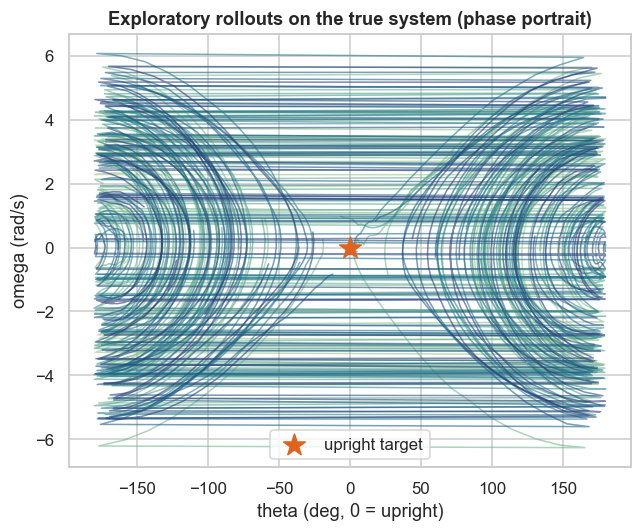

In [3]:
t0 = time.time()
states, actions, next_states = collect_random_rollouts(
    true_system, prior.action_low, prior.action_high,
    n_episodes=40, episode_len=task.explore_episode_len, seed=SEED,
    center=task.explore_center, amplitude_scale=task.explore_scale,
)
n_train = int(0.9 * len(states))
train = (states[:n_train], actions[:n_train], next_states[:n_train])
test = (states[n_train:], actions[n_train:], next_states[n_train:])
print(f"collected {len(states)} transitions ({n_train} train / {len(states) - n_train} held-out) "
      f"in {time.time() - t0:.1f}s")

fig, ax = plt.subplots(figsize=(6, 5))
episode_len = task.explore_episode_len
n_episodes = len(states) // episode_len
colors = sns.color_palette("crest", n_episodes)
for ep in range(n_episodes):
    sl = slice(ep * episode_len, (ep + 1) * episode_len)
    ax.plot(np.degrees(states[sl, 0]), states[sl, 1], color=colors[ep], alpha=0.6, lw=1.0)
ax.scatter([0], [0], marker="*", s=220, color=PALETTE["uncertainty"], zorder=5, label="upright target")
ax.set_xlabel("theta (deg, 0 = upright)")
ax.set_ylabel("omega (rad/s)")
ax.set_title("Exploratory rollouts on the true system (phase portrait)")
ax.legend()
fig.tight_layout()


## 3. Training the physics-residual ensemble

`ResidualEnsembleWorldModel` trains `K` bootstrapped, independently
initialised residual MLPs on `s' - f_phys(s, a)`. It is fully generic over
the task: it reads `state_dim`, `feature_dim` and `circular_dims` (here just
`theta`, the pendulum's only angular dimension) straight off `prior`.

trained 5 members in 38.6s


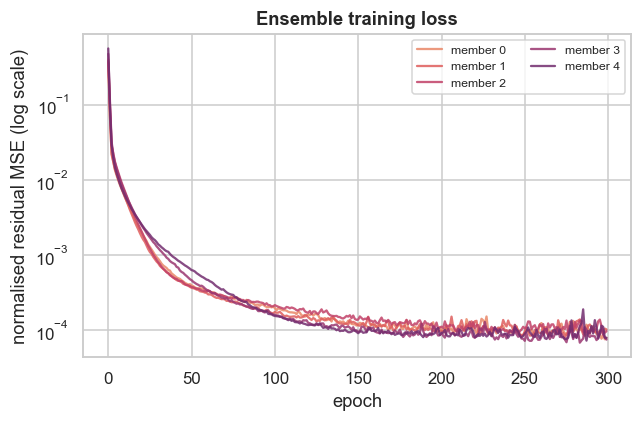

In [4]:
model = ResidualEnsembleWorldModel(prior, n_members=5, hidden=(64, 64), seed=SEED)
t0 = time.time()
histories = model.fit(*train, epochs=300)
print(f"trained {model.n_members} members in {time.time() - t0:.1f}s")

fig, ax = plt.subplots(figsize=(6, 4))
for k, h in enumerate(histories):
    ax.plot(h, color=sns.color_palette("flare", len(histories))[k], alpha=0.85, label=f"member {k}")
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("normalised residual MSE (log scale)")
ax.set_title("Ensemble training loss")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()


## 4. Prediction error: analytic prior vs. residual ensemble

Held-out one-step RMSE, broken down **per state dimension**. On the quadrotor
the prior's roll dynamics are exact and the residual learns to leave them
alone. Here the prior is wrong almost everywhere: misidentified mass and
length distort the gravity-torque term itself, and friction is entirely
unmodelled. So residual learning is not selective here. It cuts error hugely
on *both* `theta` and `omega`, roughly **148x** overall.

overall RMSE  prior: 0.0527   residual ensemble: 0.0004   (147.9x reduction)


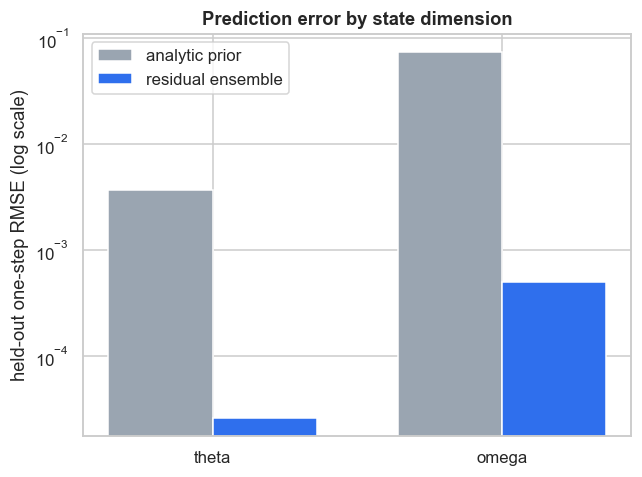

In [5]:
def rmse_per_dim(pred, target):
    err = prior.wrap_state(pred - target)
    return np.sqrt(np.mean(err**2, axis=0))

pred_prior = prior.forward(*test[:2])
pred_model, _ = model.predict(*test[:2])
err_prior = rmse_per_dim(pred_prior, test[2])
err_model = rmse_per_dim(pred_model, test[2])

dims = ["theta", "omega"]
eps = 1e-6
fig, ax = plt.subplots(figsize=(6, 4.5))
x = np.arange(len(dims))
width = 0.36
ax.bar(x - width / 2, err_prior + eps, width, color=PALETTE["prior"], label="analytic prior")
ax.bar(x + width / 2, err_model + eps, width, color=PALETTE["model"], label="residual ensemble")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(dims)
ax.set_ylabel("held-out one-step RMSE (log scale)")
ax.set_title("Prediction error by state dimension")
ax.legend()
fig.tight_layout()

overall_prior = np.sqrt(np.mean(prior.wrap_state(pred_prior - test[2]) ** 2))
overall_model = np.sqrt(np.mean(prior.wrap_state(pred_model - test[2]) ** 2))
print(f"overall RMSE  prior: {overall_prior:.4f}   residual ensemble: {overall_model:.4f}   "
      f"({overall_prior / overall_model:.1f}x reduction)")


## 5. Epistemic uncertainty heat map

The quadrotor's 6D state needs a 2D slice with the other values held fixed.
The pendulum's state *is* already the 2D `(theta, omega)` plane, so we can
sweep the ensemble's disagreement `d(s, a)` over the **entire** state space
directly, at zero torque, with the training data overlaid. Disagreement
should stay low across the well-covered swing (all of `theta`, moderate
`omega`) and grow in the unvisited high-speed corners. That is the model
"knowing what it doesn't know."

mean disagreement near training distribution (|omega| < 4): 0.00024
mean disagreement in the far corners (|omega| > 6, OOD)   : 0.00093
ratio: 3.8x


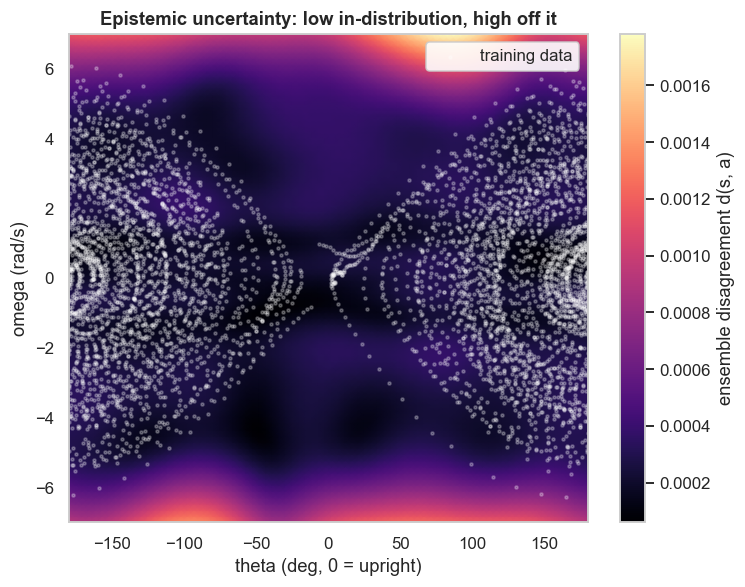

In [6]:
theta_grid = np.linspace(-np.pi, np.pi, 80)
omega_grid = np.linspace(-7.0, 7.0, 80)
TT, OM = np.meshgrid(theta_grid, omega_grid)
n_grid = TT.size

s_grid = np.stack([TT.ravel(), OM.ravel()], axis=-1)
a_grid = np.zeros((n_grid, prior.action_dim))

_, disagreement = model.predict(s_grid, a_grid)
D = disagreement.reshape(TT.shape)

fig, ax = plt.subplots(figsize=(7, 5.5))
mesh = ax.pcolormesh(np.degrees(TT), OM, D, shading="gouraud", cmap="magma")
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("ensemble disagreement d(s, a)")
ax.scatter(np.degrees(states[:, 0]), states[:, 1], s=4, color="white", alpha=0.25, label="training data")
ax.set_xlabel("theta (deg, 0 = upright)")
ax.set_ylabel("omega (rad/s)")
ax.set_title("Epistemic uncertainty: low in-distribution, high off it")
ax.legend(loc="upper right", framealpha=0.9)
fig.tight_layout()

in_dist_mask = np.abs(OM) < 4.0
ood_mask = np.abs(OM) > 6.0
print(f"mean disagreement near training distribution (|omega| < 4): {D[in_dist_mask].mean():.5f}")
print(f"mean disagreement in the far corners (|omega| > 6, OOD)   : {D[ood_mask].mean():.5f}")
print(f"ratio: {D[ood_mask].mean() / D[in_dist_mask].mean():.1f}x")


## 6. Closed-loop swing-up with CEM: prior vs. residual, optimistic vs. risk-aware

Finally, [`CEMPlanner`](src/phyres/planners/cem.py) drives the *true* system
in closed loop from a hanging start (`theta = pi`, hanging straight down),
under three world models:

1. **prior only**: the misspecified analytic model, no learning at all;
2. **residual, optimistic**: the trained ensemble, no uncertainty penalty
   (`lambda = 0`);
3. **residual, uncertainty-penalised**: the same ensemble, penalising
   imagined trajectories by `uncertainty_weight * disagreement`
   (`lambda = task.default_uncertainty_weight`).

This is the pendulum's standout result. Swinging a heavier, longer,
frictional pendulum up to vertical needs *systematically correct* energy
pumping over several swings, so a one-step-accurate model is not a nicety
here. The misspecified prior alone is expected to **fail to swing up at
all**, while the hybrid model should reliably stabilise upright.

In [7]:
class PriorOnlyModel:
    # Adapter: analytic prior exposed through the world-model interface.
    def __init__(self, prior):
        self.prior = prior

    def predict(self, state, action):
        return self.prior.forward(state, action), np.zeros(state.shape[0])


variants = {
    "prior only": (PriorOnlyModel(prior), 0.0),
    "residual, optimistic": (model, 0.0),
    "residual, uncertainty-penalised": (model, task.default_uncertainty_weight),
}

T = task.eval_horizon
results = {}
for name, (world_model, lam) in variants.items():
    planner = CEMPlanner(
        world_model, task.cost_fn,
        action_dim=prior.action_dim, action_low=prior.action_low, action_high=prior.action_high,
        horizon=task.plan_horizon, n_samples=300, n_elites=30, n_iters=4,
        uncertainty_weight=lam, init_mean=task.planner_init_mean, seed=SEED,
    )
    planner.reset()
    s = true_system.reset(state=task.initial_state)
    trajectory, actions_, costs = [s.copy()], [], []
    t0 = time.time()
    for _ in range(T):
        a = planner.plan(s)
        costs.append(float(task.cost_fn(s[None, :], a[None, :])[0]))
        actions_.append(a.copy())
        s = true_system.step(a)
        trajectory.append(s.copy())
    trajectory = np.array(trajectory)
    results[name] = {
        "trajectory": trajectory,
        "actions": np.array(actions_),
        "cost": np.array(costs),
    }
    final_theta = abs(wrap_angle(np.array([trajectory[-1, 0]]))[0])
    print(f"{name:32s} total cost={results[name]['cost'].sum():9.1f}  "
          f"final |theta|={final_theta:.3f} rad  "
          f"{'UPRIGHT' if final_theta < 0.25 else 'failed'}  ({time.time() - t0:.0f}s)")


prior only                       total cost=   2104.4  final |theta|=2.890 rad  failed  (2s)


residual, optimistic             total cost=    766.9  final |theta|=0.021 rad  UPRIGHT  (119s)


residual, uncertainty-penalised  total cost=    766.7  final |theta|=0.011 rad  UPRIGHT  (115s)


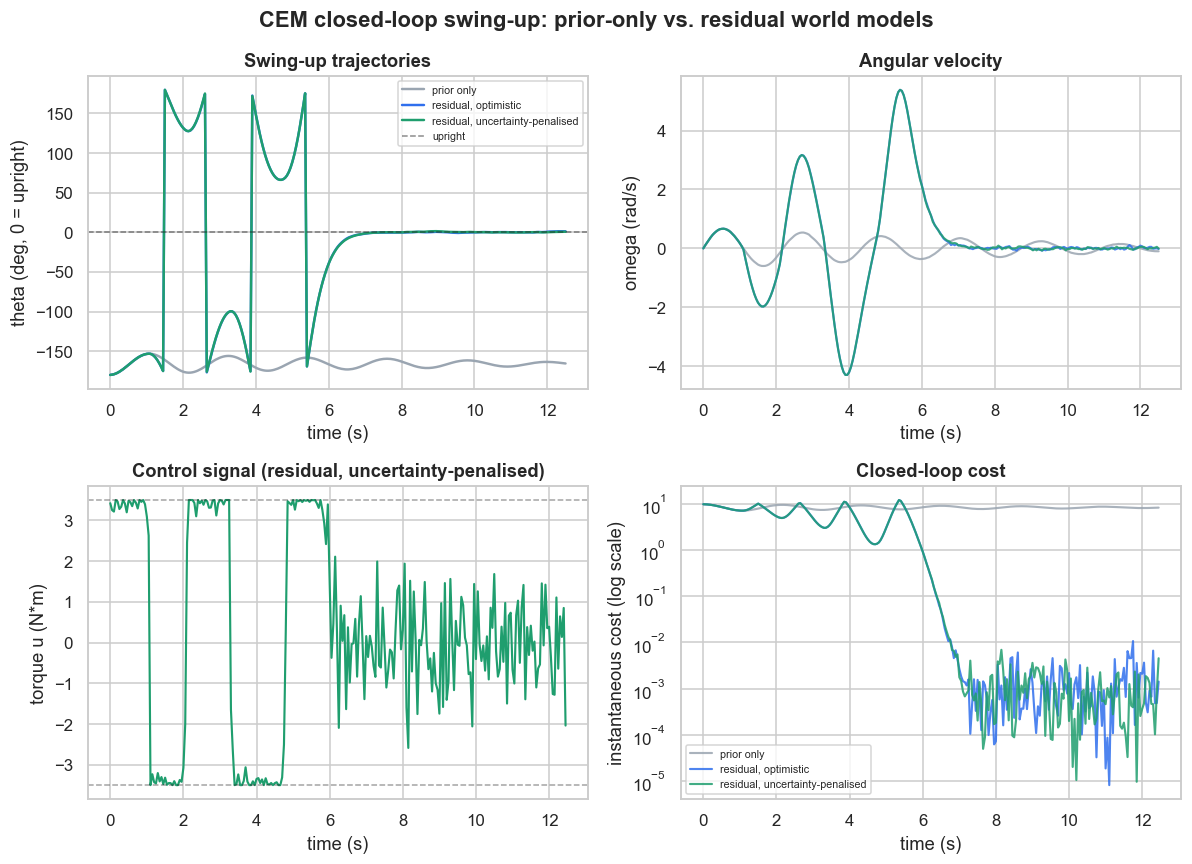

In [8]:
t = np.arange(T + 1) * true_system.dt
colors = {"prior only": PALETTE["prior"], "residual, optimistic": PALETTE["model"],
          "residual, uncertainty-penalised": PALETTE["trajectory"]}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

ax = axes[0, 0]
for name, res in results.items():
    ax.plot(t, np.degrees(wrap_angle(res["trajectory"][:, 0])), color=colors[name], lw=1.6, label=name)
ax.axhline(0.0, color="k", lw=1, ls="--", alpha=0.5, label="upright")
ax.set_xlabel("time (s)")
ax.set_ylabel("theta (deg, 0 = upright)")
ax.set_title("Swing-up trajectories")
ax.legend(fontsize=7)

ax = axes[0, 1]
for name, res in results.items():
    ax.plot(t, res["trajectory"][:, 1], color=colors[name], lw=1.4, alpha=0.85, label=name)
ax.set_xlabel("time (s)")
ax.set_ylabel("omega (rad/s)")
ax.set_title("Angular velocity")

ax = axes[1, 0]
best = "residual, uncertainty-penalised"
ax.plot(t[:-1], results[best]["actions"][:, 0], color=colors[best], lw=1.4)
ax.axhline(prior.u_max, color="k", lw=1, ls="--", alpha=0.4)
ax.axhline(-prior.u_max, color="k", lw=1, ls="--", alpha=0.4)
ax.set_xlabel("time (s)")
ax.set_ylabel("torque u (N*m)")
ax.set_title(f"Control signal ({best})")

ax = axes[1, 1]
for name, res in results.items():
    ax.plot(t[:-1], res["cost"], color=colors[name], lw=1.4, alpha=0.85, label=name)
ax.set_yscale("log")
ax.set_xlabel("time (s)")
ax.set_ylabel("instantaneous cost (log scale)")
ax.set_title("Closed-loop cost")
ax.legend(fontsize=7)

fig.suptitle("CEM closed-loop swing-up: prior-only vs. residual world models", fontweight="bold")
fig.tight_layout()


## Summary

* **Section 4** showed the residual ensemble cuts held-out one-step
  prediction error by roughly **148x** overall. Unlike the quadrotor, the
  improvement is not selective: the misidentified mass/length and the
  unmodelled friction terms corrupt *every* dimension of the prior, so the
  residual has real work to do everywhere.
* **Section 5** showed the ensemble's disagreement is structured exactly the
  way the theory predicts across the pendulum's entire state space: small
  over the well-explored swing, larger in unvisited high-speed corners. That
  is a usable epistemic-uncertainty signal, not just noise.
* **Section 6** closed the loop and gave the suite's clearest control-level
  result. The misspecified analytic prior, planned against alone, **fails to
  swing up at all** (it systematically underestimates the dissipation it must
  pump energy against). The physics-residual model, with or without the
  uncertainty penalty, reliably drives the pendulum to a stable upright
  balance from a full hanging start.

See [SCIENCE.md](SCIENCE.md) for the full formulation, and
`experiments/run_swingup.py` / `experiments/run_benchmark.py --task
<pendulum|cartpole|quadrotor2d> --planner <cem|mppi>` to reproduce this or
any other task/planner combination from the command line.